# Pemodelan dan Simulasi Sistem Dinamik: Saldo Token Listrik Prabayar

Rizki Hasan Fauzi | NIM 301240071 | Kelas 5B Teknik Informatika | UNIBBA

Saldo token listrik (kWh) diperlakukan seperti isi tangki: token yang dibeli adalah **inlet**, pemakaian alat rumah adalah **outlet**.

$$\frac{dS(t)}{dt} = u_i(t) - \frac{P(t)}{1000}$$

- $S(t)$ : saldo token (kWh)
- $u_i(t)$ : laju pengisian token (kWh/jam)
- $P(t)$ : total daya semua alat yang menyala (Watt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# parameter (asumsi, ganti sesuai kondisi rumah / tagihan sendiri)
TARIF = 1444.70                 # Rp per kWh
TOKEN_RP = 100000               # nominal token (Rp)
KWH_TOKEN = TOKEN_RP / TARIF    # kWh yang didapat dari satu kali isi
print(f"Token Rp{TOKEN_RP:,} = {KWH_TOKEN:.2f} kWh")

Token Rp100,000 = 69.22 kWh


## Program 1: Pengisian token tanpa pemakaian

Seperti tangki dengan kran outlet tertutup: $\frac{dS}{dt} = u_i$. Token Rp100.000 diisi pada jam ke-2 selama 1 jam. Saldo awal 0 kWh.

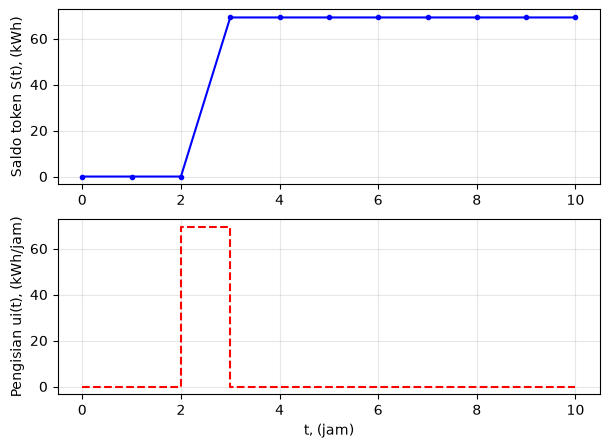

In [2]:
def token(S, t, ui, p_beban):
    # dS/dt = ui - P/1000  (kWh per jam)
    return ui - p_beban / 1000.0

ts1 = np.linspace(0, 10, 11)       # 0..10 jam, tiap 1 jam
ui1 = np.zeros(11)
ui1[2] = KWH_TOKEN                 # isi token pada interval jam 2 - 3

S = 0.0
z1 = np.zeros(11)
for i in range(10):
    # ui1[i] berlaku pada interval [t_i, t_i+1]
    y = odeint(token, S, [0, 1], args=(ui1[i], 0.0))
    S = y[-1][0]
    z1[i + 1] = S

plt.figure(figsize=(7, 5))
plt.subplot(2, 1, 1)
plt.plot(ts1, z1, 'b-o', ms=3)
plt.ylabel('Saldo token S(t), (kWh)')
plt.subplot(2, 1, 2)
plt.step(ts1, ui1, 'r--', where='post')
plt.ylabel('Pengisian ui(t), (kWh/jam)')
plt.xlabel('t, (jam)')
plt.show()

## Program 2: Saldo token dengan pemakaian alat rumah

Seperti tangki dengan outlet dikendalikan. Alat yang dimodelkan:

| Alat | Daya | Jam nyala |
|---|---|---|
| Kulkas (rata-rata) | 100 W | 24 jam |
| Lampu LED (5 buah x 10 W) | 50 W | 18.00 - 23.00 |
| TV | 100 W | 19.00 - 22.00 |
| Rice cooker | 350 W | 05.00 - 06.00 |
| AC | 500 W | 22.00 - 06.00 |

Saldo awal 30 kWh, simulasi 10 hari (240 jam), isi token Rp100.000 pada jam ke-84.

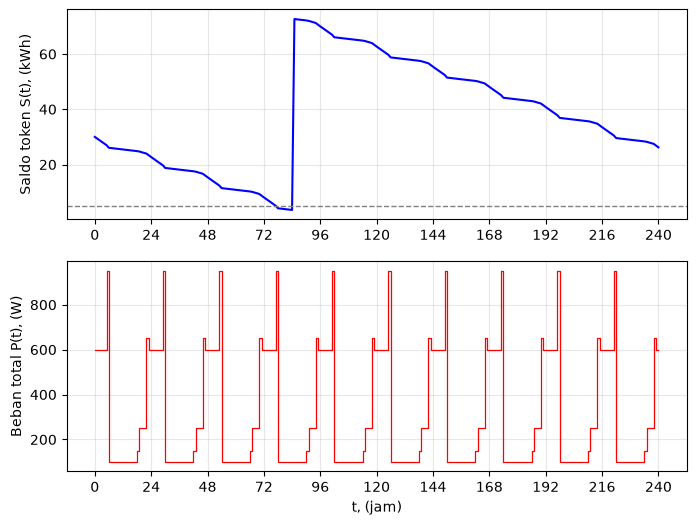

Pemakaian per hari : 7.3 kWh
Saldo sebelum isi  : 3.55 kWh
Saldo setelah isi  : 72.67 kWh
Saldo akhir (240 j): 26.22 kWh


In [3]:
def beban(ac_jam=8):
    ts = np.arange(0, 241)          # 0..240 jam, tiap 1 jam
    h = ts % 24                     # jam dalam sehari
    kulkas = np.full(241, 100.0)
    lampu  = np.where((h >= 18) & (h < 23), 50.0, 0.0)
    tv     = np.where((h >= 19) & (h < 22), 100.0, 0.0)
    rc     = np.where(h == 5, 350.0, 0.0)
    if ac_jam > 0:
        ac_on = (h >= 22) | (h < (22 + ac_jam - 24))
    else:
        ac_on = np.zeros(241, dtype=bool)
    ac = np.where(ac_on, 500.0, 0.0)
    return ts, kulkas + lampu + tv + rc + ac

def simulasi(ac_jam=8, S0=30.0, t_isi=84):
    ts, p = beban(ac_jam)
    ui = np.zeros(241)
    ui[t_isi] = KWH_TOKEN
    z = np.zeros(241)
    z[0] = S0
    S = S0
    for i in range(240):
        y = odeint(token, S, [0, 1], args=(ui[i], p[i]))
        S = y[-1][0]
        z[i + 1] = S
    return ts, z, p, ui

ts, z2, p2, ui2 = simulasi(ac_jam=8)

plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(ts, z2, 'b-')
plt.axhline(5, color='gray', ls='--', lw=1)
plt.ylabel('Saldo token S(t), (kWh)')
plt.xticks(range(0, 241, 24))
plt.subplot(2, 1, 2)
plt.step(ts, p2, 'r-', where='post', lw=0.9)
plt.ylabel('Beban total P(t), (W)')
plt.xlabel('t, (jam)')
plt.xticks(range(0, 241, 24))
plt.show()

print("Pemakaian per hari :", p2[:24].sum() / 1000, "kWh")
print("Saldo sebelum isi  :", round(z2[84], 2), "kWh")
print("Saldo setelah isi  :", round(z2[85], 2), "kWh")
print("Saldo akhir (240 j):", round(z2[240], 2), "kWh")

## Program 3: Variasi lama pemakaian AC

Seperti Contoh 2 pada materi (variasi nilai $k$), di sini yang divariasikan adalah lama AC menyala per malam: 0, 4, dan 8 jam.

AC 0 jam: saldo sebelum isi = 18.55 kWh, akhir = 66.22 kWh
AC 4 jam: saldo sebelum isi = 11.55 kWh, akhir = 46.22 kWh
AC 8 jam: saldo sebelum isi = 3.55 kWh, akhir = 26.22 kWh


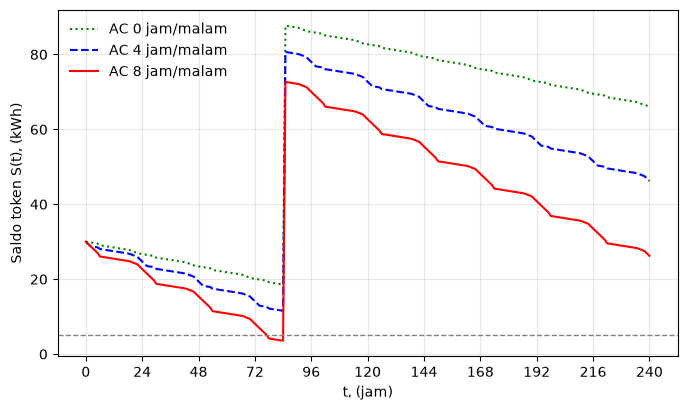

In [4]:
plt.figure(figsize=(8, 4.5))
for aj, c, ls in ((0, 'g', ':'), (4, 'b', '--'), (8, 'r', '-')):
    t_, z_, p_, u_ = simulasi(ac_jam=aj)
    plt.plot(t_, z_, c=c, ls=ls, label=f'AC {aj} jam/malam')
    print(f"AC {aj} jam: saldo sebelum isi = {z_[84]:.2f} kWh, akhir = {z_[240]:.2f} kWh")
plt.axhline(5, color='gray', ls='--', lw=1)
plt.xlabel('t, (jam)')
plt.ylabel('Saldo token S(t), (kWh)')
plt.xticks(range(0, 241, 24))
plt.legend(frameon=False)
plt.show()

## Program 4: Versi GEKKO

Persamaan yang sama dengan Program 2, diselesaikan memakai GEKKO (IMODE = 4, simulasi dinamik).

In [5]:
%pip install gekko -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


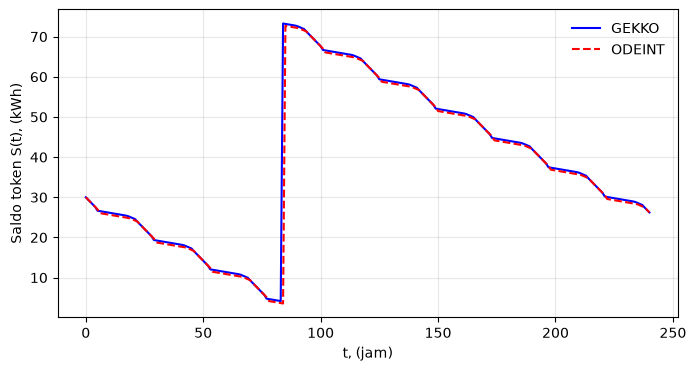

In [6]:
from gekko import GEKKO

ts, p = beban(ac_jam=8)
ui = np.zeros(241)
ui[84] = KWH_TOKEN

m = GEKKO(remote=False)
m.time = np.linspace(0, 240, 241)
u_in = m.Param(value=ui)           # laju pengisian (kWh/jam)
p_load = m.Param(value=p)          # beban total (W)

S = m.Var(30.0)                    # saldo awal 30 kWh
m.Equation(S.dt() == u_in - p_load / 1000.0)

m.options.IMODE = 4
m.solve(disp=False)

plt.figure(figsize=(8, 4))
plt.plot(m.time, S.value, 'b-', label='GEKKO')
plt.plot(ts, z2, 'r--', label='ODEINT')
plt.xlabel('t, (jam)')
plt.ylabel('Saldo token S(t), (kWh)')
plt.legend(frameon=False)
plt.show()

## Program 5: Simulasi steady state

Steady state terjadi saat $\frac{dS}{dt} = 0$, yaitu pengisian sama dengan pemakaian ($u_i = P/1000$). Dua kasus disimulasikan dengan jadwal beban yang sama seperti Program 2 (AC 8 jam), saldo awal 30 kWh, dan batas peringatan 5 kWh:

- **Kasus A:** pengisian selalu sama dengan pemakaian sesaat, $u_i(t) = P(t)/1000$. Saldo tetap 30 kWh (steady state sejati).
- **Kasus B:** pengisian konstan sebesar pemakaian rata-rata, $u_i = 7{,}3/24 \approx 0{,}304$ kWh/jam. Saldo naik-turun dalam sehari dan kembali ke 30 kWh tiap 24 jam (steady state periodik).

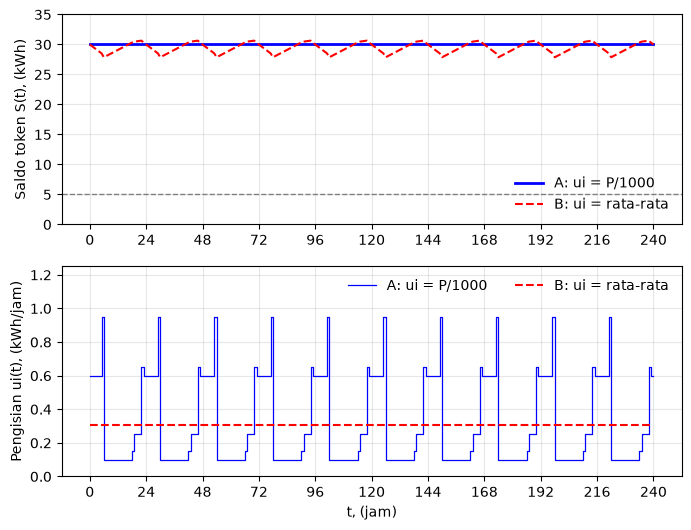

ui rata-rata       : 0.3042 kWh/jam
Kasus A  S min/max : 30.00 / 30.00 kWh
Kasus B  S min/max : 27.88 / 30.64 kWh
Kasus B  S(24)=30.00, S(48)=30.00, S(240)=30.00 kWh


In [7]:
ts, p = beban(ac_jam=8)
uo = p / 1000.0                          # laju pemakaian (kWh/jam)

def simulasi_ui(ui, S0=30.0):
    z = np.zeros(241)
    z[0] = S0
    S = S0
    for i in range(240):
        y = odeint(token, S, [0, 1], args=(ui[i], p[i]))
        S = y[-1][0]
        z[i + 1] = S
    return z

# Kasus A: pengisian selalu sama dengan pemakaian (steady state sejati)
ui_A = uo.copy()
zA = simulasi_ui(ui_A)

# Kasus B: pengisian konstan = pemakaian rata-rata (steady state periodik)
ui_B = np.full(241, uo[:24].mean())
zB = simulasi_ui(ui_B)

plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(ts, zA, 'b-', lw=2, label='A: ui = P/1000')
plt.plot(ts, zB, 'r--', label='B: ui = rata-rata')
plt.axhline(5, color='gray', ls='--', lw=1)
plt.ylabel('Saldo token S(t), (kWh)')
plt.ylim(0, 35)
plt.xticks(range(0, 241, 24))
plt.legend(frameon=False, loc='lower right')
plt.subplot(2, 1, 2)
plt.step(ts, ui_A, 'b-', where='post', lw=0.9, label='A: ui = P/1000')
plt.step(ts, ui_B, 'r--', where='post', label='B: ui = rata-rata')
plt.ylabel('Pengisian ui(t), (kWh/jam)')
plt.xlabel('t, (jam)')
plt.xticks(range(0, 241, 24))
plt.ylim(0, 1.25)
plt.legend(frameon=False, loc='upper right', ncol=2)
plt.show()

print(f"ui rata-rata       : {uo[:24].mean():.4f} kWh/jam")
print(f"Kasus A  S min/max : {zA.min():.2f} / {zA.max():.2f} kWh")
print(f"Kasus B  S min/max : {zB.min():.2f} / {zB.max():.2f} kWh")
print(f"Kasus B  S(24)={zB[24]:.2f}, S(48)={zB[48]:.2f}, S(240)={zB[240]:.2f} kWh")